# Πρόβλεψη ανθρώπινων αποφάσεων υπό αβεβαιότητα

Ονοματεπώνυμο φοιτητή: Ζωή Γιαγλή



## Εισαγωγή

Στην παρούσα εργασία θα χρησιμοποιηθεί το σύνολο δεδομένων choices13k, το οποίο περιέχει χιλιάδες προβλήματα λήψης αποφάσεων υπό αβεβαιότητα.

Σε κάθε πρόβλημα οι συμμετέχοντες καλούνται να επιλέξουν ανάμεσα σε δύο εναλλακτικές επιλογές/ στοιχήματα, το 'Gamble A' και 'Gamble B'. Κάθε επιλογή οι συμμετέχοντες ήξεραν τις πιθανές αποδόσεις και τις αντίστοιχες πιθανότητες εμφάνισής τους. Το 'Gamble A' είχε δύο μόνο πιθανά αποτελέσματα, ενώ το 'Gamble B' συνδύαζε μια σταθερή απόδοση με μια λοταρία που μπορούσε να έχει διαφορετικά αποτελέσματα ανάλογα με το πρόβλημα.

Στόχος της εργασίας είναι η κατασκευή μοντέλων μηχανικής μάθησης που μπορούν να προβλέψουν όσο το δυνατόν ακριβέστερα τη μεταβλητή 'bRate', η οποία εκφράζει το ποσοστό των συμμετεχόντων που επέλεξαν το 'Gamble B' για κάθε πρόβλημα.

## Εισαγωγή βιβλιοθηκών 

Θα χρησιμοποιηθούν οι παρακάτω βιβλιοθήκες:

- json: Ανάγνωση και την αποσυμπίεση του αρχείου `c13k_problems.json`, το οποίο περιέχει τις πλήρεις πιθανοτικές κατανομές των στοιχημάτων.
- numpy: Γρήγοροι αριθμητικοί υπολογισμοί και διαχείριση πινάκων.
- pandas: Φόρτωση, συγχώνευση και μετασχηματισμός των πειραματικών δεδομένων.
- matplotlib: Οπτικοποίηση των δεδομένων.
- scipy.stats (sem): Υπολογισμός του τυπικού σφάλματος του μέσου όρου (Standard Error of the Mean) για την εκτίμηση της αβεβαιότητας των μετρήσεων.
- optuna: Αυτοματοποιημένη βελτιστοποίηση υπερπαραμέτρων (Hyperparameter Tuning).


Από τη βιβλιοθήκη scikit-learn χρησιμοποιούνται:

- train_test_split: Διαχωρισμός των δεδομένων σε σύνολο εκπαίδευσης (Train Set) και σύνολο ελέγχου (Test Set)
- KFold: Στρατηγική αναδίπλωσης (K-Fold) για τη σωστή διαμέριση των δεδομένων κατά τη διασταυρωμένη επικύρωση.
- cross_validate: Αξιολόγηση των μοντέλων με διασταυρωμένη επικύρωση (Cross-validation).
- permutation_importance: Εκτίμηση σημαντικότητας των χαρακτηριστικών στο τελικό μοντέλο (Feature Importance).
- LinearRegression: Το βασικό γραμμικό μοντέλο αναφοράς (Baseline Model).
- DecisionTreeRegressor: Δημιουργία μοντέλων δέντρων απόφασης.
- RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor: Εκπαίδευση Ensemble μοντέλων παλινδρόμησης.
- mean_absolute_error, mean_squared_error, r2_score: Aξιολόγηση της απόδοσης των μοντέλων.

In [85]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import sem
import optuna

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_validate
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

## Φόρτωση και ανάλυση δεδομένων

Χρησιμοποιούνται τα αρχεία:

- `c13k_selections.csv`, το αρχείο αυτό περιέχει τα χαρακτηριστικά κάθε προβλήματος καθώς και τη μεταβλητή 'bRate'.
- `c13k_problems.json`, το αρχείο αυτό περιέχει την πλήρη περιγραφή των δύο επιλογών (Gamble A και Gamble B) για κάθε πρόβλημα (αριθμός αποτελεσμάτων, πιθανότητες, αποδόσεις).

In [86]:
df = pd.read_csv("c13k_selections.csv")

with open("c13k_problems.json", "r") as f:
    problems = json.load(f)

df.head()

,Problem,Feedback,n,Block,Ha,pHa,La,Hb,pHb,Lb,LotShapeB,LotNumB,Amb,Corr,bRate,bRate_std
0,1,True,15,2,26,0.95,-1,23,0.05,21,0,1,False,0,0.626667,0.384460
1,2,True,15,4,14,0.60,-18,8,0.25,-5,0,1,True,-1,0.493333,0.413118
2,3,True,17,4,2,0.50,0,1,1.00,1,0,1,False,0,0.611765,0.432843
3,4,True,18,3,37,0.05,8,87,0.25,-31,1,2,False,0,0.222222,0.387383
4,5,False,15,1,26,1.00,26,45,0.75,-36,2,5,False,0,0.586667,0.450185


Έπειτα, εξετάζουμε τη δομή του συνόλου δεδομένων, δηλαδή το πλήθος των παρατηρήσεων, το πλήθος των μεταβλητών, τους τύπους δεδομένων κάθε στήλης, αλλά και την ύπαρξη πιθανών ελλιπών τιμών. Ο σκοπός είναι να γίνει κατανοητή η δομή των δεδομένων.

In [87]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14568 entries, 0 to 14567
Data columns (total 16 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Problem    14568 non-null  int64  
 1   Feedback   14568 non-null  bool   
 2   n          14568 non-null  int64  
 3   Block      14568 non-null  int64  
 4   Ha         14568 non-null  int64  
 5   pHa        14568 non-null  float64
 6   La         14568 non-null  int64  
 7   Hb         14568 non-null  int64  
 8   pHb        14568 non-null  float64
 9   Lb         14568 non-null  int64  
 10  LotShapeB  14568 non-null  int64  
 11  LotNumB    14568 non-null  int64  
 12  Amb        14568 non-null  bool   
 13  Corr       14568 non-null  int64  
 14  bRate      14568 non-null  float64
 15  bRate_std  14568 non-null  float64
dtypes: bool(2), float64(4), int64(10)
memory usage: 1.6 MB


Άρα βλέπουμε πως το σύνολο δεδομένων αποτελείται από 14.568 παρατηρήσεις και 16 μεταβλητές. Δεν υπάρχουν ελλιπή δεδομένα, εφόσον όλες οι στήλες περιέχουν 14.568 μη κενές τιμές. Επιπλέον, οι περισσότερες μεταβλητές είναι αριθμητικές ('int64' και 'float64'). Υπάρχουν και δύο boolean μεταβλητές ('Feedback' και 'Amb'), οι οποίες καταγράφουν τις συνθήκες του πειράματος και θα χρειαστεί να μετατραπούν σε αριθμητικές (0/ 1) στη συνέχεια. Το γεγονός ότι δεν υπάρχουν ελλιπές τιμές και οι πλειοψηία των μεταβλητών είναι ήδη σε αριθμητική μορφή, διευκολύνει το στάδιο της προετοιμασίας των δεδομένων.

## Οπτικοποίηση της μεταβλητής 'bRate'

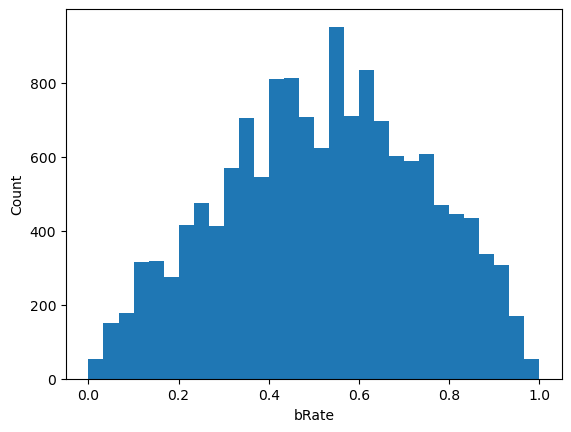

In [88]:
plt.hist(df["bRate"], bins=30)
plt.xlabel("bRate")
plt.ylabel("Count")
plt.show()

Από το γράφημα φαίνεται πως η μεταβλητή 'bRate' λαμβάνει τιμές σε ολόκληρο το διάστημα [0,1]. Οι περισσότερες παρατηρήσεις εμφανίζονται στις κεντρικές τιμές, ενώ στα άκρα οι παρατηρήσεις είναι εμφανώς λιγότερες. Από την κατανομή της μεταβλητής μπορούμε να καταλάβουμε πως υπάρχει αρκετή διακύμανση στις επιλογές των συμμετεχόντων, και άρα το πρόβλημα είναι κατάλληλο για εφαρμογή μοντέλων παλινδρόμησης.

## Προεπεξεργασία δεδομένων και δημιουργία νέων χαρακτηριστικών

#### Αφαίρεση της μεταβλητής 'bRate_std'

Αρχικά, θα αφαιρέσουμε τη μεταβλητή 'bRate_std' διότι:

- υπολογίζεται αφού έχει ολοκληρωθεί η πειραματική διαδικασία και αφού έχουν συλλεχθεί όλες οι αποφάσεις των συμμετεχόντων. Το μοντέλο που θα φτιάξουμε θέλουμε να δέχεται ένα άγνωστο πρόβλημα και να μπορεί να προβλέψει τη συμπεριφορά των ανθρώπων και σε πραγματικές συνθήκες πρόβλεψης η τιμή του bRate_std' δεν γίνεται να είναι γνωστή εκ των προτέρων.
- υπάρχει κίνδυνος διαρροής δεδομένων (data leakage), καθώς η μεταβλητή 'bRate' και η 'bRate_std' συνδέονται άμεσα.

In [89]:
df = df.drop(columns=["bRate_std"])

#### Υπάρχοντα χαρακτηριστικά

Πριν δημιουργηθούν νέα χαρακτηριστικά, εξετάζονται τα αρχικά του αρχείου CSV. Διατηρούνται όσα περιγράφουν τα ίδια τα gambles ή τις συνθήκες παρουσίασής τους, ενώ αφαιρούνται αναγνωριστικά και μεταβλητές που δεν είναι διαθέσιμες σε πραγματικές συνθήκες πρόβλεψης.

- `Ha`, `La`, `pHa`: Είναι η υψηλή/ χαμηλή απόδοση του Gamble A και η πιθανότητα της υψηλής απόδοσης του Gamble A. Περιγράφουν πλήρως το Gamble A, ορίζουν το εύρος των αποτελεσμάτων και είναι απαραίτητα για τον υπολογισμό παράγωγων χαρακτηριστικών. (Διατηρούνται)

- `Hb`, `Lb`, `pHb`: Η υψηλή/ χαμηλή βασική απόδοση του Gamble B και η πιθανότητα της υψηλής απόδοσης του Gamble B. Περιγράφουν τα βασικά χαρακτηριστικά του Gamble B και επομένως αποτελούν απαραίτητη πληροφορία για την πρόβλεψη της συμπεριφοράς των συμμετεχόντων. (Διατηρούνται)

- `LotShapeB`: Η δομή της λοταρίας του Gamble B (π.χ. ομοιόμορφη, φθίνουσα, αύξουσα κατανομή), η οποία μπορεί να επηρεάσει την αντίληψη του κινδύνου από τους συμμετέχοντες. (Διατηρείται)

- `LotNumB`: Ο αριθμός των αποτελεσμάτων στη λοταρία του Gamble B. Μεγάλος αριθμός αποτελεσμάτων αυξάνει την πολυπλοκότητα της επιλογής και μπορεί να επηρεάσει τη συμπεριφορά των συμμετεχόντων. (Διατηρείται)

- `Feedback`: Δηλώνει αν οι συμμετέχοντες λάμβαναν ανατροφοδότηση μετά από κάθε επιλογή, κάτι που μπορεί να οδηγήσει τους συμμετέχοντες στο να κάνουν καλύτερες επιλογές επειδή μαθαίνουν από τα αποτελέσματα των προηγούμενων επιλογών τους. (Διατηρείται)

- `Amb`: Δείχνει αν το πρόβλημα περιείχε αβεβαιότητα ή ασάφεια ως προς τις πιθανότητες, κάτι που μπορεί να επηρεάσει τη διαδικασία λήψης αποφάσεων. (Διατηρείται)

- `Corr`: Η συσχέτιση μεταξύ των αποτελεσμάτων των δύο gambles όταν παίζονται ταυτόχρονα. Θετική συσχέτιση σημαίνει ότι και τα δύο αποδίδουν καλά ή κακά μαζί, κάτι που επηρεάζει τη σχετική ελκυστικότητά τους. (Διατηρείται)

- `n`, `Block`: Διατηρούνται καθώς παρέχουν πληροφορία για το πειραματικό πλαίσιο μέσα στο οποίο συλλέχθηκαν οι απαντήσεις. Η μεταβλητή n δείχνει πόσοι συμμετέχοντες απάντησαν σε κάθε πρόβλημα, ενώ η 'Block' δείχνει σε ποιο στάδιο του πειράματος παρουσιάστηκε το πρόβλημα. 

- `Problem`: Αποτελεί απλώς αναγνωριστικό του προβλήματος και δεν περιέχει ουσιαστική πληροφορία για τη συμπεριφορά των συμμετεχόντων, οπότε αφαιρείται.

In [90]:
df = df.drop(columns=["Problem"])

df["Feedback"] = df["Feedback"].astype(int)
df["Amb"] = df["Amb"].astype(int)

Παραπάνω, μαζί με την αφαίρεση της μεταβλητής 'problem' γίνεται και η μετατροπή των λογικών μεταβλητών 'Feedback' και 'Amb' σε αριθμητική μορφή για να μπορούν να χρησιμοποιηθούν από τα μοντέλα μηχανικής μάθησης.

#### Δημιουργία νέων χαρακτηριστικών

#### Αναμενόμενες αξίες

Σε αυτό το βήμα υπολογίζουμε την αναμενόμενη αξία (Expected Value) του 'Gamble A' και του 'Gamble B' με βάση τις αποδόσεις και τις πιθανότητες των δύο επιλογών. Η τιμή αυτή εκφράζει το μέσο κέρδος ή ζημία που αναμένεται να προκύψει από μία επιλογή όταν αυτή επαναλαμβάνεται πολλαπλές φορές υπό τις ίδιες συνθήκες. Ο υπολογισμός της πραγματοποιείται ως το σταθμισμένο άθροισμα των πιθανών αποδόσεων, όπου κάθε απόδοση πολλαπλασιάζεται με την αντίστοιχη πιθανότητά της. Θα δημιουργήσουμε επίσης, την 'ev_diff' που εκφράζει τη διαφορά των δύο αναμενόμενων αξιών, γιατί το πιθανότερο είναι πως οι συμμετέχοντες δεν αξιολογούν τις δύο επιλογές ανεξάρτητα, αλλά να τις συγκρίνουν μεταξύ τους.

In [91]:
df["ev_A"] = df["pHa"] * df["Ha"] + (1 - df["pHa"]) * df["La"]
df["ev_B"] = df["pHb"] * df["Hb"] + (1 - df["pHb"]) * df["Lb"]
df["ev_diff"] = df["ev_B"] - df["ev_A"]

#### Πρόσθετα χαρακτηριστικά από το αρχείο JSON

Από το αρχείο 'c13k_problems.json' θα αξιοποιήσουμε την πλήρη περιγραφή των δύο επιλογών για κάθε πρόβλημα για να δημιουργήσουμε επιπλέον χαρακτηριστικά και έτσι να περιγράψουμε καλύτερα τα δύο gambles. Το αρχείο CSV περιέχει μόνο τις μεταβλητές Hb, Lb, pHb του Gamble B (υψηλή και χαμηλή τιμή), και δεν λαμβάνει υπόψη ότι το Gamble B μπορεί να έχει έως 9 διαφορετικά αποτελέσματα (κάτι που φαίνεται στη δομή του αρχείου JSON). Για το Gamble A πάντα υπάρχουν ακριβώς δύο αποτελέσματα, οπότε το CSV το περιγράφει πλήρως.

Παρακάτω, για κάθε gamble υπολογίζονται:

- η πιθανότητα θετικής απόδοσης,
- η πιθανότητα αρνητικής απόδοσης,
- η διακύμανση των αποδόσεων,
- η μέγιστη πιθανή απόδοση,
- η ελάχιστη πιθανή απόδοση.

Η πιθανότητα θετικής/ αρνητικής απόδοσης είναι χρήσιμη, καθώς οι συμμετέχοντες μπορεί να επηρεάζονται όχι μόνο από τη μέση απόδοση μιας επιλογής, αλλά και από το πόσο πιθανό είναι να προκύψει κέρδος ή ζημία. Η διακύμανση χρησιμοποιείται ως μέτρο κινδύνου, καθώς δείχνει πόσο απλωμένα είναι τα πιθανά αποτελέσματα γύρω από την αναμενόμενη αξία και ένα gamble με μεγάλη διακύμανση θεωρείται πιο ριψοκίνδυνο από ένα gamble με μικρότερη διακύμανση. Η μέγιστη και ελάχιστη απόδοση αντιπροσωπεύουν το «καλύτερο» και «χειρότερο» σενάριο γι΄αυτό επηρεάζουν τη λήψη αποφάσεων ανεξάρτητα από τη μέση αξία. Τέλος, χρησιμοποιούμε τις διαφορές των αντίστοιχων χαρακτηριστικών μεταξύ του Gamble B και του Gamble A, επειδή η επιλογή είναι εγγενώς συγκριτική.

In [92]:
def get_features(gamble):
    p = np.array([x[0] for x in gamble])
    x = np.array([x[1] for x in gamble])
    
    ev = np.sum(p * x)
    p_gain = np.sum(p[x > 0])
    p_loss = np.sum(p[x < 0])
    var = np.sum(p * (x - ev) ** 2)
    max_x = np.max(x)
    min_x = np.min(x)
    
    return ev, p_gain, p_loss, var, max_x, min_x

Έπειτα, θα εφαρμοστεί η συνάρτηση σε όλα τα προβλήματα του αρχείου JSON και θα υπολιστούν τα αντίστοιχα χαρακτηριστικά για το Gamble A και το Gamble B. Οι τιμές αποθηκεύονται προσωρινά σε λίστες και στη συνέχεια θα χρησιμοποιηθούν για τη δημιουργία νέων χαρακτηριστικών στο βασικό dataframe.

In [93]:
ev_a = []
ev_b = []
gain_a = []
gain_b = []
loss_a = []
loss_b = []
var_a = []
var_b = []
max_a = []
max_b = []
min_a = []
min_b = []

for i in range(len(df)):
    problem = problems[str(i)]

    a = get_features(problem["A"])
    b = get_features(problem["B"])

    ev_a.append(a[0])
    ev_b.append(b[0])
    gain_a.append(a[1])
    gain_b.append(b[1])
    loss_a.append(a[2])
    loss_b.append(b[2])
    var_a.append(a[3])
    var_b.append(b[3])
    max_a.append(a[4])
    max_b.append(b[4])
    min_a.append(a[5])
    min_b.append(b[5])

Πριν χρησιμοποιήσουμε τις αναμενόμενες αξίες που προκύπτουν από το αρχείο JSON, ελέγχουμε αν συμφωνούν με τις αντίστοιχες αναμενόμενες αξίες που υπολογίστηκαν από το CSV. Έτσι, θα αποφύγουμε τη δημιουργία διπλών χαρακτηριστικών που περιγράφουν στην ουσία την ίδια πληροφορία.

In [94]:
corr_a = np.corrcoef(df["ev_A"], ev_a)[0, 1]
corr_b = np.corrcoef(df["ev_B"], ev_b)[0, 1]
diff_a = df["ev_A"].values - np.array(ev_a)
diff_b = df["ev_B"].values - np.array(ev_b)

print("Correlation ev_A:", corr_a)
print("Correlation ev_B:", corr_b)
print("Max difference ev_A:", np.abs(diff_a).max())
print("Max difference ev_B:", np.abs(diff_b).max())

Correlation ev_A: 1.0
Correlation ev_B: 1.0
Max difference ev_A: 0.0
Max difference ev_B: 2.3092638912203256e-14


Από τα αποτελέσματα φαίνεται ότι οι αναμενόμενες αξίες που υπολογίζονται από το αρχείο CSV και από το αρχείο JSON ταυτίζονται.
Η συσχέτιση μεταξύ των δύο υπολογισμών είναι ίση με 1, ενώ οι διαφορές που παρατηρούνται είναι μηδενικές ή αμελητέες (2.3092638912203256e-14) και οφείλονται σε περιορισμούς αριθμητικής ακρίβειας. Άρα οι μεταβλητές 'ev_A' και 'ev_B' που έχουν ήδη υπολογιστεί από το CSV διατηρούνται στο dataset και δεν δημιουργούνται επιπλέον αντίστοιχες μεταβλητές από το JSON.

Έχοντας υπολογίσει τα χαρακτηριστικά και για τα δύο gambles, δημιουργούμε νέα χαρακτηριστικά που εκφράζουν τις διαφορές μεταξύ τους. Η χρήση διαφορών αντί των αρχικών τιμών είναι σημαντική, γιατί ο στόχος μας είναι να προβλέψουμε πόσο συχνά επιλέγεται το Gamble B έναντι του Gamble A. Επομένως, τα χαρακτηριστικά αυτά δείχνουν αν το Gamble B υπερτερεί ή υστερεί ως προς την πιθανότητα κέρδους, την πιθανότητα ζημίας, τον κίνδυνο και τα ακραία πιθανά αποτελέσματα.

In [95]:
df["diff_gain"] = np.array(gain_b) - np.array(gain_a)
df["diff_loss"] = np.array(loss_b) - np.array(loss_a)
df["diff_var"] = np.array(var_b) - np.array(var_a)
df["diff_max"] = np.array(max_b) - np.array(max_a)
df["diff_min"] = np.array(min_b) - np.array(min_a)

#### Τελικό σύνολο χαρακτηριστικών

Μετά την προεπεξεργασία των δεδομένων και τη δημιουργία νέων χαρακτηριστικών, παρακάτω φαίνεται το τελικό σύνολο των χαρακτηριστικών:

In [96]:
print(df.columns.tolist())

['Feedback', 'n', 'Block', 'Ha', 'pHa', 'La', 'Hb', 'pHb', 'Lb', 'LotShapeB', 'LotNumB', 'Amb', 'Corr', 'bRate', 'ev_A', 'ev_B', 'ev_diff', 'diff_gain', 'diff_loss', 'diff_var', 'diff_max', 'diff_min']


## Δημιουργία συνόλων εκπαίδευσης και ελέγχου (Train-Test Split)

Σε αυτό το σημείο ορίζουμε τη μεταβλητή στόχο που θέλουμε να προβλέψουμε (δηλαδή τη 'bRate') και τα χαρακτηριστικά που θα χρησιμοποιηθούν από τα μοντέλα. Έπειτα χωρίζουμε τα δεδομένα σε σύνολο εκπαίδευσης και σύνολο ελέγχου (με random_state=42 για αναπαραγωγιμότητα), ώστε να μπορέσουμε να αξιολογήσουμε πόσο καλά γενικεύουν τα μοντέλα σε νέα δεδομένα.

In [97]:
X = df.drop(columns=["bRate"])
y = df["bRate"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (11654, 21)
Test set: (2914, 21)


Το σύνολο εκπαίδευσης περιλαμβάνει 11.654 παρατηρήσεις και 21 χαρακτηριστικά, ενώ το σύνολο ελέγχου περιλαμβάνει 2.914 παρατηρήσεις με τα ίδια χαρακτηριστικά.

## Εκπαίδευση και αξιολόγηση μοντέλων

Σε αυτό το σημείο θα γίνει η εκπαίδευση και αξιολόγηση των διαφορετικών μοντέλων παλινδρόμησης που στοχεύουν στην πρόβλεψη του 'bRate'.

#### Γραμμική παλινδρόμηση

Αρχικά θα πραγματοποιηθεί γραμμική παλινδρόμηση (Linear Regression), η οποία αποτελεί ένα από τα πιο βασικά μοντέλα και θα χρησιμοποιηθεί ως σημείο αναφοράς (baseline). Στον παρακάτω κώδικα δημιουργούμε και εκπαιδεύουμε το μοντέλο χρησιμοποιώντας το σύνολο εκπαίδευσης. Μετά πραγματοποιούμε προβλέψεις για το σύνολο ελέγχου και υπολογίζουμε τις μετρικές MAE, RMSE και $R^2$ για να αξιολογήσουμε την απόδοσή του.

In [98]:
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)
y_pred = lin_reg.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 0.11655178290751218
RMSE: 0.14515432840122156
R2: 0.5696290821624648


Η τιμή MAE είναι περίπου 0.1165, οπότε οι προβλέψεις αποκλίνουν κατά μέσο όρο περίπου 0.12 μονάδες από τις πραγματικές τιμές της μεταβλητής 'bRate'.
Η τιμή του RMSE (0.1451) δείχνει ότι τα σφάλματα των προβλέψεων παραμένουν σε σχετικά χαμηλά επίπεδα, ακόμη και όταν λαμβάνονται υπόψη οι μεγαλύτερες αποκλίσεις. Ο συντελεστής προσδιορισμού R^2 είναι περίπου 0.57 που σημαίνει ότι το μοντέλο εξηγεί σχεδόν το 57% της διακύμανσης της μεταβλητής στόχου.

Τα αποτελέσματα αυτά μπορούμε να τα θεωρήσουμε ικανοποιητικά για ένα απλό γραμμικό μοντέλο και θα χρησιμοποιηθούν ως σημείο αναφοράς για τη σύγκριση με πιο σύνθετα μοντέλα που θα εξεταστούν παρακάτω.

#### Δέντρο απόφασης (Decision Tree)

Μετά τη Γραμμική Παλινδρόμηση θα δοκιμάσουμε ένα Δέντρο Απόφασης (Decision Tree Regressor). Σε αντίθεση με αυτή, το δέντρο απόφασης μπορεί να αποτυπώσει μη γραμμικές σχέσεις μεταξύ των χαρακτηριστικών και της μεταβλητής στόχου. Ο παρακάτω κώδικας αξιοποιεί πάλι το σύνολο εκπαίδευσης για τη δημιουργία και εκπαίδευση του μοντέλου. Έπειτα πραγματοποιούνται προβλέψεις στο σύνολο ελέγχου και υπολογίζονται ξανά οι μετρικές MAE, RMSE και $R^2$.

In [99]:
tree = DecisionTreeRegressor(random_state=42)
tree.fit(X_train, y_train)
y_pred = tree.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 0.10972615783106736
RMSE: 0.14161157158500215
R2: 0.5903806915637624


Από τα παραπάνω αποτελέσματα μπορούμε να δούμε ότι η απόδοση του Δέντρου Απόφασης είναι καλύτερη από εκείνη της Γραμμικής Παλινδρόμησης.
Πιο αναλυτικά, η τιμή του MAE μειώνεται σε περίπου 0.109, οπότε οι προβλέψεις του μοντέλου είναι κατά μέσο όρο πιο κοντά στις πραγματικές τιμές της μεταβλητής 'bRate'. Επίσης, η τιμή του RMSE είναι περίπου 0.141 και ο συντελεστής προσδιορισμού R^2 αυξάνεται σε περίπου 0.59, κάτι που σημαίνει ότι το μοντέλο εξηγεί μεγαλύτερο ποσοστό της διακύμανσης της μεταβλητής στόχου.

Οι τιμές αυτές δείχνουν ότι η δυνατότητα του δέντρου απόφασης να μοντελοποιεί μη γραμμικές σχέσεις μεταξύ των χαρακτηριστικών και της μεταβλητής στόχου οδηγεί σε καλύτερη απόδοση σε σχέση με τη Γραμμική Παλινδρόμηση.

#### Random Forest

Το τρίτο μοντέλο που θα δοκιμαστεί είναι το Random Forest που αποτελεί επέκταση των δέντρων απόφασης και βασίζεται στη δημιουργία πολλών διαφορετικών δέντρων, τα οποία εκπαιδεύονται σε διαφορετικά υποσύνολα των δεδομένων. Οι προβλέψεις όλων αυτών των δέντρων συνδυάζονται ώστε να προκύψει η τελική πρόβλεψη. Έτσι, μειώνεται η ευαισθησία που παρουσιάζει ένα μεμονωμένο δέντρο απόφασης και μπορούμε να πετύχουμε καλύτερη γενίκευση σε νέα δεδομένα.

Στον παρακάτω κώδικα εκπαιδεύουμε το μοντέλο χρησιμοποιώντας πάλι το σύνολο εκπαίδευσης και στη συνέχεια αξιολογούμε την απόδοσή του στο σύνολο ελέγχου με τις ίδιες μετρικές που χρησιμοποιήσαμε και στα προηγούμενα μοντέλα.

In [100]:
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 0.07862534161887019
RMSE: 0.10072982862495083
R2: 0.7927478115791265


Από τις παραπάνω τιμές είναι φανερό πως η απόδοση του Random Forest είναι σημαντικά καλύτερη από αυτή των προηγούμενων μοντέλων. Βλέπουμε πως το MAE μειώνεται σε περίπου 0.0786 και άρα οι προβλέψεις του μοντέλου βρίσκονται κατά μέσο όρο πολύ πιο κοντά στις πραγματικές τιμές της μεταβλητής 'bRate'. Η τιμή του RMSE μειώνεται σε περίπου 0.1007 και ο συντελεστής προσδιορισμού R^2 αυξάνεται σε περίπου 0.792. Η τιμή αυτή σημαίνει ότι το μοντέλο εξηγεί το 79% της διακύμανσης της μεταβλητής στόχου.

Οπότε ο συνδυασμός πολλών δέντρων απόφασης επιτρέπει στο μοντέλο να περιγράφει αποτελεσματικότερα τις σχέσεις μεταξύ των χαρακτηριστικών και της μεταβλητής στόχου, οδηγώντας σε καλύτερη γενίκευση σε νέα δεδομένα.

#### Extra Trees

Το επόμενο μοντέλο είναι το Extra Trees Regressor (Extremely Randomized Trees). Παρομοίως με το προηγούμενο μοντέλο, χρησιμοποιείται ένα σύνολο δέντρων απόφασης, αλλά στο Extra Trees εισάγεται περισσότερη τυχαιότητα κατά τη δημιουργία τους. Πιο συγκεκριμένα, σε κάθε διαχωρισμό (split) εξετάζεται ένα τυχαίο υποσύνολο χαρακτηριστικών και αντί να αναζητείται το βέλτιστο σημείο διαχωρισμού για κάθε χαρακτηριστικό, επιλέγονται τυχαία υποψήφια σημεία και στη συνέχεια κρατάμε το καλύτερο από αυτά. Έτσι, μπορεί να μειωθεί ακόμα περισσότερο το overfitting και να πετύχουμε καλύτερη γενίκευση σε νέα δεδομένα.

Στον παρακάτω κελί εκπαιδεύουμε το μοντέλο και τυπώνουμε τις ίδιες μετρικές (MAE, $R^2$, RMSE) για να δούμε πώς τα πηγαίνει σε σχέση με τα προηγούμενα.

In [101]:
extra_trees = ExtraTreesRegressor(random_state=42)
extra_trees.fit(X_train, y_train)
y_pred = extra_trees.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 0.07812496498035144
RMSE: 0.09975694800474752
R2: 0.7967318931408234


Η απόδοση του Extra Trees είναι πολύ κοντά σε αυτή του Random Forest, με λίγο καλύτερα αποτελέσματα και στις τρεις μετρικές αξιολόγησης.
Πιο συγκεκριμένα, το μοντέλο επιτυγχάνει MAE περίπου 0.0781 και RMSE περίπου 0.099, ενώ ο συντελεστής προσδιορισμού R^2 είναι περίπου 0.796.

#### Gradient Boosting

Το επόμενο μοντέλο, δηλαδή το Gradient Boosting, ακολουθεί διαφορετική προσέγγιση από τα προηγούμενα που έχουν εξεταστεί, καθώς τα δέντρα δημιουργούνται διαδοχικά και κάθε νέο δέντρο προσπαθεί να διορθώσει τα σφάλματα των προηγούμενων. Εφόσον τα δέντρα δεν είναι ανεξάρτητα, το μοντέλο μπορεί να μάθει σταδιακά πιο σύνθετες σχέσεις μεταξύ των χαρακτηριστικών και της μεταβλητής στόχου. 

Στον παρακάτω κελί εκπαιδεύουμε το μοντέλο χρησιμοποιώντας το σύνολο εκπαίδευσης και αξιολογούμε την απόδοσή του στο σύνολο ελέγχου με τις ίδιες μετρικές που χρησιμοποιήσαμε και στα παραπάνω μοντέλα.

In [102]:
gbr = GradientBoostingRegressor(random_state=42)
gbr.fit(X_train, y_train)
y_pred = gbr.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 0.08348544528808981
RMSE: 0.10647264547837361
R2: 0.7684424079308455


Παρατηρώντας τα αποτελέσματα, βλέπουμε ότι η απόδοση του Gradient Boosting είναι σημαντικά καλύτερη από εκείνη της Γραμμικής Παλινδρόμησης και του μεμονωμένου δέντρου απόφασης. Το μοντέλο επιτυγχάνει μέσο σφάλμα περίπου 0.0834, το RMSE παραμένει σε χαμηλά επίπεδα, δηλαδή περίπου 0.1064 και ο συντελεστής προσδιορισμού R^2 φτάνει περίπου στο 0.768. 

Ωστόσο, το Gradient Boosting έχει ελαφρώς χειρότερη απόδοση από το Random Forest και  το Extra Trees, τα οποία παραμένουν τα καλύτερα μοντέλα μέχρι στιγμής.

#### Hist Gradient Boosting

Το έκτο και τελευταίο μοντέλο που θα εξετάσουμε είναι το Hist Gradient Boosting Regressor, το οποίο είναι μια βελτιστοποιημένη παραλλαγή του κλασικού Gradient Boosting που χρησιμοποιεί ιστογράμματα (histograms) για τον υπολογισμό των πιθανών διαχωρισμών των χαρακτηριστικών. Η προσέγγιση αυτή μειώνει σημαντικά το υπολογιστικό κόστος και επιτρέπει την ταχύτερη εκπαίδευση του μοντέλου, ιδιαίτερα σε μεγάλα σύνολα δεδομένων, ενώ διατηρεί τα βασικά πλεονεκτήματα του Gradient Boosting, δηλαδή τη διαδοχική δημιουργία δέντρων που προσπαθούν να διορθώσουν τα σφάλματα των προηγούμενων.

Στο επόμενο κελί κώδικα πραγματοποιείται η εκπαίδευση του μοντέλου και η αξιολόγησή του με βάση τις καθορισμένες μετρικές (MAE, RMSE, $R^2$).

In [103]:
hist_gbr = HistGradientBoostingRegressor(random_state=42)
hist_gbr.fit(X_train, y_train)
y_pred = hist_gbr.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2:", r2)

MAE: 0.07509269683217648
RMSE: 0.09578507006393622
R2: 0.8125961203648226


Η απόδοση του Hist Gradient Boosting φαίνεται να είναι η καλύτερη από όλα τα παραπάνω μοντέλα που εξετάστηκαν.

Αναλυτικότερα, το μοντέλο έχει τιμή MAE περίπου 0.0751, RMSE περίπου 0.0958 και συντελεστή προσδιορισμού R^2 κοντά στο 0.813, δηλαδή τιμές καλύτερες από εκείνες των Random Forest, Extra Trees και Gradient Boosting. Τα αποτελέσματα δείχνουν ότι το μοντέλο καταφέρνει να περιγράψει αποτελεσματικά τη σχέση μεταξύ των χαρακτηριστικών και της μεταβλητής στόχου, επιτυγχάνοντας τη μικρότερη απόκλιση μεταξύ προβλέψεων και πραγματικών τιμών.

## Cross-validation

Παρακάτω θα εφαρμόσουμε 5-fold cross-validation στα τρία μοντέλα που είχαν την καλύτερη απόδοση μέχρι στιγμής: Hist Gradient Boosting, Extra Trees και Random Forest. Έτσι, αξιολογείται κάθε μοντέλο σε περισσότερους διαφορετικούς διαχωρισμούς των δεδομένων και παίρνουμε μια πιο σταθερή εκτίμηση της απόδοσής του, καθώς η αξιολόγηση βάσει ενός μόνο test set μπορεί να εξαρτάται από τον συγκεκριμένο διαχωρισμό των δεδομένων.

In [104]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Hist Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        scoring=["neg_mean_absolute_error", "r2", "neg_root_mean_squared_error"],
        cv=cv,
        n_jobs=-1
    )

    print(name)
    print("MAE:", np.mean(-scores["test_neg_mean_absolute_error"]), sem(-scores["test_neg_mean_absolute_error"]))
    print("RMSE:", np.mean(-scores["test_neg_root_mean_squared_error"]), sem(-scores["test_neg_root_mean_squared_error"]))
    print("R2:", np.mean(scores["test_r2"]), sem(scores["test_r2"]))
    print()

Hist Gradient Boosting
MAE: 0.07829773751123245 8.186922869187086e-05
RMSE: 0.09875153381998558 0.0002917415503429162
R2: 0.8018147589904775 0.0030227200657336212

Extra Trees
MAE: 0.08034003212797713 0.0001658494182274541
RMSE: 0.10127588190189743 0.0003114070918574338
R2: 0.7915343002838681 0.003478409137070046

Random Forest
MAE: 0.08138191055535232 0.00019706520694646334
RMSE: 0.10294143559272864 0.00037032045092933
R2: 0.7846154004495673 0.003698036395168688



Από τα παραπάνω αποτελέσματα του 5-fold cross-validation φαίνεται ότι το Hist Gradient Boosting επιτυγχάνει τη συνολικά καλύτερη απόδοση, με μέσο MAE περίπου 0.0783, μέσο RMSE περίπου 0.0988 και μέσο συντελεστή προσδιορισμού περίπου 0.802. Αυτές οι τιμές είναι καλύτερες από εκείνες των Extra Trees και Random Forest.

Και τα τρία μοντέλα εμφανίζουν σταθερή απόδοση στα διαφορετικά folds, όπως φαίνεται από τις χαμηλές τιμές του τυπικού σφάλματος.

Οπότε θα επιλέξουμε το Hist Gradient Boosting ως το καλύτερο μοντέλο για να το χρησιμοποιήσουμε στη συνέχεια για βελτιστοποίηση υπερπαραμέτρων (hyperparameter tuning).

## Βελτιστοποίηση υπερπαραμέτρων (Hyperparameter Tuning)

Η βελτιστοποίηση των υπερπαραμέτρων πραγματοποιείται με τη βιβλιοθήκη Optuna στο μοντέλο Hist Gradient Boosting. Το Optuna δοκιμάζει διαφορετικούς συνδυασμούς υπερπαραμέτρων για να βρει εκείνους που οδηγούν στη μικρότερη τιμή MAE μέσω 5-fold cross-validation.

In [105]:
def objective(trial):

    params = {
        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            0.3,
            log=True
        ),

        "max_iter": trial.suggest_int(
            "max_iter",
            100,
            1000
        ),

        "max_depth": trial.suggest_int(
            "max_depth",
            3,
            15
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf",
            10,
            100
        ),

        "l2_regularization": trial.suggest_float(
            "l2_regularization",
            1e-4,
            10,
            log=True
        ),

        "max_leaf_nodes": trial.suggest_int(
            "max_leaf_nodes",
            15,
            255
        )
    }

    model = HistGradientBoostingRegressor(
        random_state=42,
        **params
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        scoring="neg_mean_absolute_error",
        cv=5,
        n_jobs=-1
    )

    return -scores["test_score"].mean()

In [106]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))

study.optimize(
    objective,
    n_trials=50
)

In [107]:
print("Best MAE:", study.best_value)
print()
print("Best parameters:")

for key, value in study.best_params.items():
    print(key, ":", value)

Best MAE: 0.07699707010171764

Best parameters:
learning_rate : 0.02217625609335075
max_iter : 856
max_depth : 13
min_samples_leaf : 78
l2_regularization : 0.009815384116328835
max_leaf_nodes : 151


Από τη βελτιστοποίηση των υπερπαραμέτρων προκύπτει ότι ο καλύτερος συνδυασμός επιτυγχάνει μέσο MAE περίπου 0.0770 στο 5-fold cross-validation. Οπότε, υπάρχει μια μικρή βελτίωση σε σχέση με το αρχικό αποτέλεσμα του Hist Gradient Boosting πριν τη βελτιστοποίηση, το οποίο είχε μέσο MAE περίπου 0.0783. 

Οι υπερπαράμετροι που προέκυψαν από το Optuna θα χρησιμοποιηθούν στη συνέχεια για την εκπαίδευση και αξιολόγηση του τελικού μοντέλου.

## Τελικό μοντέλο

Τώρα θα γίνει η εκπαίδευση του τελικού μοντέλου Hist Gradient Boosting, χρησιμοποιώντας τις βέλτιστες υπερπαραμέτρους που προέκυψαν από το Optuna.
Έπειτα, θα γίνει αξιολόγηση της απόδοσή του στο σύνολο ελέγχου (test), το οποίο δεν χρησιμοποιήθηκε κατά την εκπαίδευση ή τη διαδικασία βελτιστοποίησης των υπερπαραμέτρων.

In [108]:
best_model = HistGradientBoostingRegressor(
    **study.best_params,
    random_state=42
)

best_model.fit(X_train, y_train)

y_pred = best_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2:", r2_score(y_test, y_pred))

MAE: 0.07487504987579398
RMSE: 0.09546859011206243
R2: 0.8138324631367168


Τα παραπάνω αποτελέσματα δείχνουν πως το Hist Gradient Boosting επιτυγχάνει καλύτερη απόδοση σε σχέση με την αρχική του εκδοχή πριν από τη διαδικασία βελτιστοποίησης υπερπαραμέτρων. Δηλαδή, το μοντέλο επιτυγχάνει τώρα MAE περίπου 0.0748, RMSE περίπου 0.0954 και συντελεστή προσδιορισμού περίπου 0.814. Οι τιμές αυτές δείχνουν ότι το μοντέλο μπορεί να προβλέψει με αρκετά μεγάλη ακρίβεια τη μεταβλητή 'bRate', και εξηγεί περίπου το 81.4% της διακύμανσής της.

## Σημαντικότητα χαρακτηριστικών (Feature Importance)

Σε αυτό το βήμα εξετάζεται ποια χαρακτηριστικά επηρεάζουν περισσότερο τις προβλέψεις του τελικού μοντέλου μέσω της μεθόδου Permutation Importance. Πιο συγκεκριμένα, η μέθοδος αυτή ανακατεύει τυχαία τις τιμές ενός χαρακτηριστικού, σπάζοντας έτσι τη σχέση του με τη μεταβλητή στόχο, και μετράει πόσο πέφτει η απόδοση του μοντέλου. Όσο μεγαλύτερη η πτώση, τόσο πιο σημαντικό το χαρακτηριστικό. Η μέθοδος αυτή επιλέχθηκε γιατί λειτουργεί με οποιοδήποτε μοντέλο, σε αντίθεση με το built-in 'feature_importances_' που δεν είναι διαθέσιμο για το Hist Gradient Boosting. Θα παρουσιάσουμε έναν πίνακα με τα σημαντικότερα χαρακτηριστικά αλλά και ένα διάγραμμα, για να είναι πιο εύκολη η οπτική σύγκριση της σχετικής σημασίας τους.

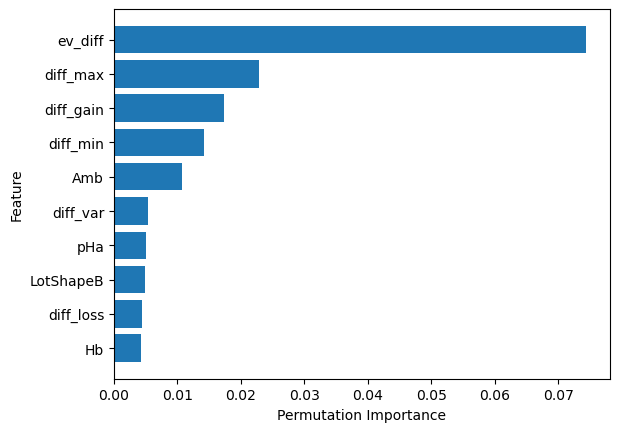

,Feature,Importance
15,ev_diff,0.074435
19,diff_max,0.022820
16,diff_gain,0.017350
20,diff_min,0.014211
11,Amb,0.010735
18,diff_var,0.005353
4,pHa,0.005037
9,LotShapeB,0.004846
17,diff_loss,0.004431
6,Hb,0.004203


In [109]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring="neg_mean_absolute_error"
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance_df.head(10)

plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Permutation Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()
plt.show()

importance_df.head(10)

Tο σημαντικότερο χαρακτηριστικό είναι το 'ev_diff' με importance = 0.0744, δηλαδή η διαφορά αναμενόμενης αξίας μεταξύ του Gamble B και του Gamble A. Αυτό είναι αναμενόμενο, καθώς οι συμμετέχοντες καλούνται να συγκρίνουν τις δύο επιλογές και η σχετική αναμενόμενη αξία αποτελεί βασική πληροφορία για την απόφασή τους. Επίσης, σημαντικό importance έχουν και τα χαρακτηριστικά 'diff_max', 'diff_gain' και 'diff_min', τα οποία περιγράφουν διαφορές στα ακραία αποτελέσματα και στην πιθανότητα κέρδους μεταξύ των δύο gambles. Αυτό δείχνει ότι το μοντέλο δεν βασίζεται μόνο στη μέση απόδοση, αλλά αξιοποιεί και πληροφορίες για το εύρος των πιθανών αποτελεσμάτων και την πιθανότητα θετικής απόδοσης. Η μεταβλητή 'Amb' εμφανίζεται επίσης αρκετά σημαντική (= 0.01), οπότε η ύπαρξη αβεβαιότητας στο πρόβλημα επηρεάζει τη συχνότητα επιλογής του Gamble B.

## Τελικό αποτέλεσμα (cross-validated MAE)

Παρακάτω εμφανίζεται η καλύτερη τιμή MAE που επιτεύχθηκε μέσω cross-validation κατά τη διαδικασία βελτιστοποίησης του τελικού μοντέλου.

In [110]:
print(study.best_value)

0.07699707010171764
